Data berhasil dimuat.

Jumlah data latih: 1532 baris
Jumlah data uji: 383 baris

Melatih model Random Forest...
Model selesai dilatih.

Evaluasi performa model...

Laporan Klasifikasi:
              precision    recall  f1-score   support

        Good       0.39      0.40      0.39       139
    Question       0.41      0.54      0.47       155
    Disagree       0.22      0.08      0.12        89

    accuracy                           0.38       383
   macro avg       0.34      0.34      0.33       383
weighted avg       0.36      0.38      0.36       383


Confusion Matrix:
[[56 70 13]
 [59 84 12]
 [30 52  7]]

Akurasi: 0.3838


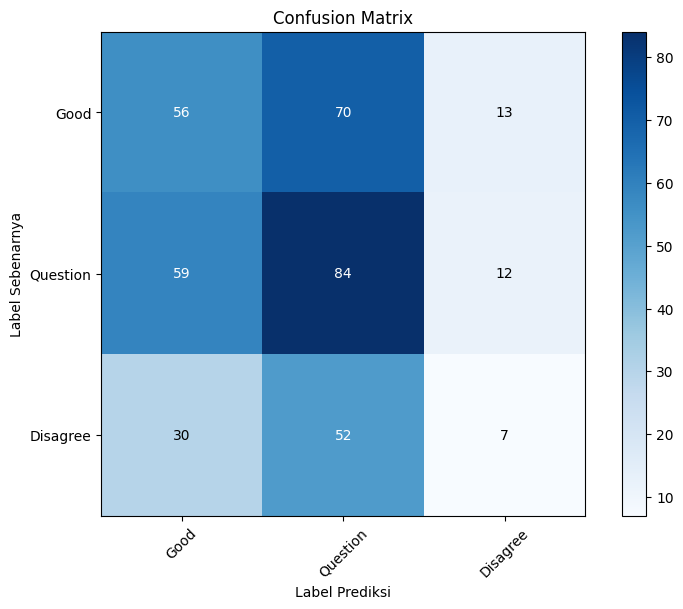

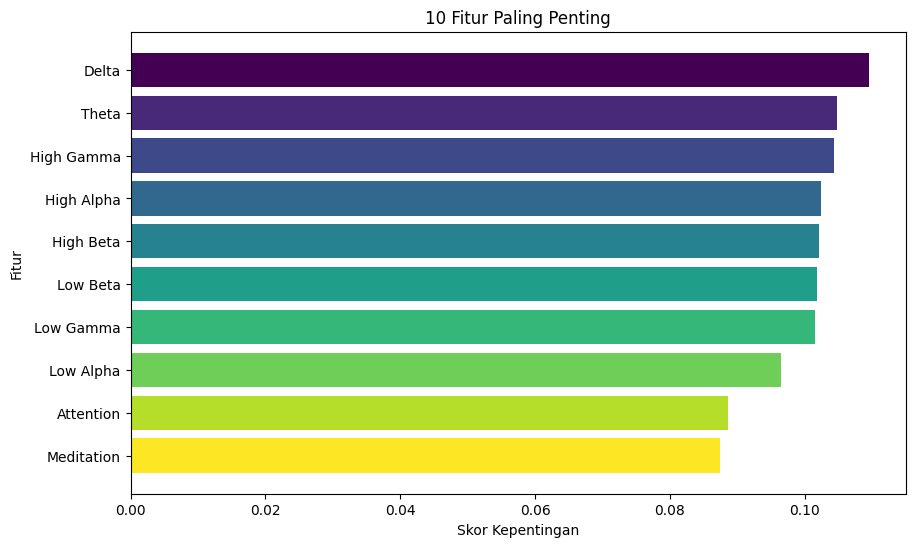

In [3]:
# Nama       : Marchell Adi Pratama
# NIM        : 672023081
# Mata Kuliah: Machine Learning

# Import modul-modul yang bakal dipakai
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# ===============================================
# Catatan untuk Bapak Dosen:
# Mohon maaf, saya telah menyesuaikan path pembacaan dataset
# dari 'c:/all.csv' menjadi 'all.csv' karena kendala teknis saat dijalankan.
# File yang digunakan tetap sama, hanya lokasi akses file disesuaikan
# agar script dapat berjalan dengan baik di lingkungan saya.
# Terima kasih atas pengertiannya.
# ===============================================

# === 1. Baca Data ===
try:
    df = pd.read_csv('all.csv')
    print("Data berhasil dimuat.")
except FileNotFoundError:
    print("Error: File 'all.csv' tidak ditemukan. Pastikan path file sudah benar.")
    exit()

# Hapus kolom pertama kalau namanya 'Unnamed: 0' (biasanya muncul sendiri pas save dari pandas)
if df.columns[0] == 'Unnamed: 0':
    df = df.drop(columns=df.columns[0])

# === 2. Siapkan Data ===

# Ambil fitur (X) dan target (y)
# Fitur = semua kolom kecuali label (Good, Question, Disagree)
X = df.drop(columns=['Good', 'Question', 'Disagree'])

# Buat label gabungan dari tiga kolom tadi
# Diasumsikan cuma satu yang True per baris
def get_combined_label(row):
    if row['Good']:
        return 0  # 0 = Good
    elif row['Question']:
        return 1  # 1 = Question
    elif row['Disagree']:
        return 2  # 2 = Disagree
    else:
        return -1  # Kalau enggak ada yang cocok

# Kasih label ke tiap baris
df['combined_label'] = df.apply(get_combined_label, axis=1)

# Ambil data yang labelnya valid aja
df_filtered = df[df['combined_label'] != -1].copy()

# Update fitur dan label dari data yang udah difilter
X = df_filtered.drop(columns=['Good', 'Question', 'Disagree', 'combined_label'])
y = df_filtered['combined_label']

# Pastikan semua fitur berupa angka
for col in X.columns:
    if X[col].dtype == 'object':
        try:
            X[col] = pd.to_numeric(X[col])
        except ValueError:
            print(f"Peringatan: Kolom '{col}' nggak bisa dikonversi jadi angka, jadi dihapus.")
            X = X.drop(columns=[col])

# Bagi data jadi latih dan uji (80% : 20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nJumlah data latih: {X_train.shape[0]} baris")
print(f"Jumlah data uji: {X_test.shape[0]} baris")

# === 3. Latih Model ===
print("\nMelatih model Random Forest...")
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
print("Model selesai dilatih.")

# === 4. Evaluasi Model ===
print("\nEvaluasi performa model...")
y_pred = model.predict(X_test)

# Tampilkan hasil klasifikasi
print("\nLaporan Klasifikasi:")
print(classification_report(y_test, y_pred, target_names=['Good', 'Question', 'Disagree']))

# Tampilkan confusion matrix
print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)

# Cek akurasi model
accuracy = accuracy_score(y_test, y_pred)
print(f"\nAkurasi: {accuracy:.4f}")

# === 5. Gambar Confusion Matrix ===
plt.figure(figsize=(8, 6))
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.colorbar()
tick_marks = np.arange(3)
plt.xticks(tick_marks, ['Good', 'Question', 'Disagree'], rotation=45)
plt.yticks(tick_marks, ['Good', 'Question', 'Disagree'])
plt.tight_layout()
plt.ylabel('Label Sebenarnya')
plt.xlabel('Label Prediksi')

# Tampilkan angka di setiap sel matrix
thresh = cm.max() / 2.
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, format(cm[i, j], 'd'),
                 ha="center", va="center",
                 color="white" if cm[i, j] > thresh else "black")
plt.show()

# === 6. Tampilkan Fitur yang Paling Berpengaruh ===
# Ambil 10 fitur paling penting dari model
feature_importances = pd.Series(model.feature_importances_, index=X.columns)
top_10_features = feature_importances.nlargest(10)

plt.figure(figsize=(10, 6))
plt.barh(top_10_features.index, top_10_features.values,
         color=plt.cm.viridis(np.linspace(0, 1, len(top_10_features))))
plt.title('10 Fitur Paling Penting')
plt.xlabel('Skor Kepentingan')
plt.ylabel('Fitur')
plt.gca().invert_yaxis()  # Biar yang penting tampil di atas
plt.show()
